# E-Commerce Sales, Customer & Profitability Analysis

## 1. Exploratory Data Analysis (EDA)

### Project Overview
This notebook focuses on analyzing the cleaned e-commerce retail dataset to identify sales trends, customer behaviour, product performance, and business profitability.

### Objectives
- Analyze overall sales and profitability.
- Identify monthly and quarterly sales trends.
- Evaluate product and category performance.
- Understand customer purchasing behaviour.
- Analyze geographical sales distribution.
- Evaluate payment methods and sales channels.
- Identify business opportunities through data-driven insights.

### Tools and Libraries
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn

### Dataset
Source: Cleaned E-Commerce Retail Dataset
Records: 5,000
Columns: 28
Period: January 2025 – December 2025

In [3]:
# Import analysis libraries and load the cleaned e-commerce dataset.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

df = pd.read_csv("../data/processed/retail_sales_cleaned.csv")

df["order_date"] = pd.to_datetime(
    df["order_date"], errors="coerce"
)

print("EDA Dataset Loaded Successfully")

EDA Dataset Loaded Successfully


In [ ]:
# Set up the directory for exporting analysis charts.
import os

chart_dir = "../outputs/charts"

os.makedirs(chart_dir, exist_ok=True)

print("Chart export directory ready:", chart_dir)

Chart export directory ready: ../outputs/charts


In [4]:
# Calculate key business performance indicators from the cleaned dataset.

total_orders = df["order_id"].nunique()
total_customers = df["customer_id"].nunique()
total_units = df["quantity"].sum()

recorded_sales = df["sales_amount"].sum()
total_profit = df["profit"].sum()
total_cost = df["cost_amount"].sum()

average_order_value = recorded_sales / total_orders
profit_margin = (total_profit / recorded_sales) * 100

delivered_sales = df.loc[
    df["order_status"] == "Delivered", "sales_amount"
].sum()

kpi_summary = pd.DataFrame({
    "Metric": [
        "Total Orders",
        "Total Customers",
        "Total Units Sold",
        "Recorded Sales",
        "Delivered Sales",
        "Total Cost",
        "Total Profit",
        "Average Order Value",
        "Profit Margin (%)"
    ],
    "Value": [
        total_orders,
        total_customers,
        total_units,
        recorded_sales,
        delivered_sales,
        total_cost,
        total_profit,
        average_order_value,
        profit_margin
    ]
})

display(kpi_summary.round(2))

,Metric,Value
0,Total Orders,5000.00
1,Total Customers,1675.00
2,Total Units Sold,11897.00
3,Recorded Sales,24240547.70
4,Delivered Sales,16346271.60
5,Total Cost,17498399.67
6,Total Profit,6742148.03
7,Average Order Value,4848.11
8,Profit Margin (%),27.81


In [5]:
# Analyze monthly sales and profit trends across the year.

monthly_sales = (
    df.dropna(subset=["order_date"])
    .assign(month=lambda x: x["order_date"].dt.to_period("M"))
    .groupby("month")
    .agg(
        total_orders=("order_id", "nunique"),
        total_sales=("sales_amount", "sum"),
        total_profit=("profit", "sum")
    )
    .reset_index()
)

monthly_sales["month"] = monthly_sales["month"].astype(str)

display(monthly_sales.round(2))

,month,total_orders,total_sales,total_profit
0,2025-01,451,2187864.26,636775.07
1,2025-02,403,2083365.09,563152.69
2,2025-03,434,1984907.38,558273.71
3,2025-04,416,1983909.42,550945.33
4,2025-05,435,1992227.45,541648.28
5,2025-06,417,2106792.38,579522.20
6,2025-07,427,2057319.88,544504.74
7,2025-08,410,2094886.95,592765.24
8,2025-09,355,1684862.56,466326.07
9,2025-10,400,1864667.93,533199.52


/var/folders/01/sgd5rw450c32b5c1ts5pl0vm0000gn/T/ipykernel_62792/1921075241.py:29: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/01/sgd5rw450c32b5c1ts5pl0vm0000gn/T/ipykernel_62792/1921075241.py:30: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  plt.savefig(
/Users/sanjeevjha/Desktop/Retail-Sales-Analysis/venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


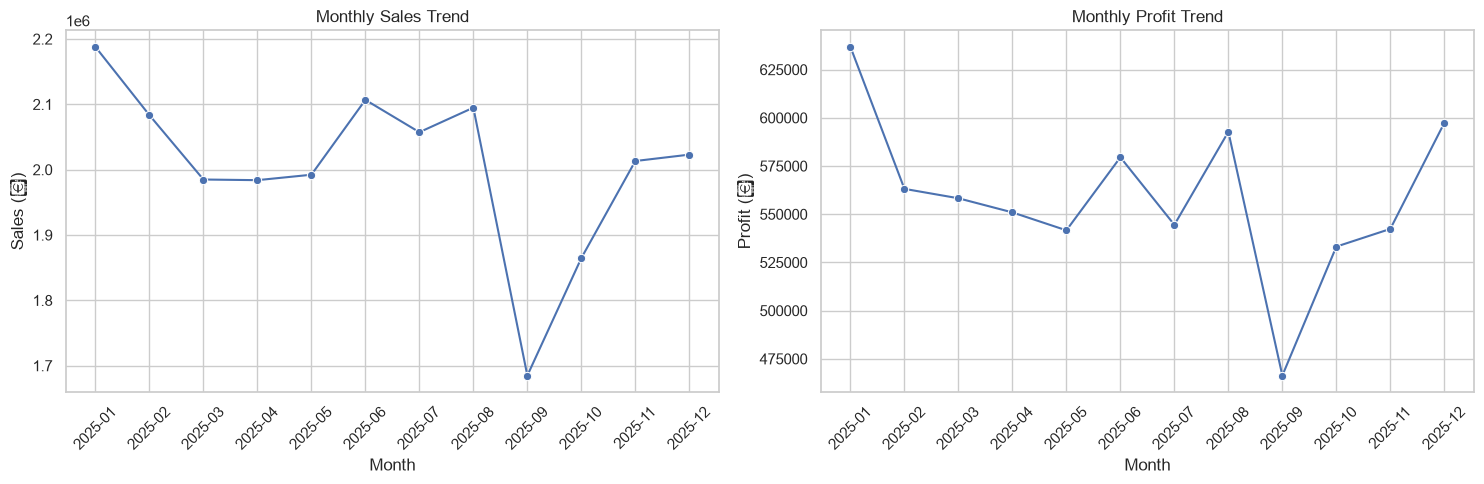

In [43]:
# Visualize monthly sales and profit trends for 2025.

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.lineplot(
    data=monthly_sales,
    x="month",
    y="total_sales",
    marker="o",
    ax=axes[0]
)
axes[0].set_title("Monthly Sales Trend")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Sales (₹)")
axes[0].tick_params(axis="x", rotation=45)

sns.lineplot(
    data=monthly_sales,
    x="month",
    y="total_profit",
    marker="o",
    ax=axes[1]
)
axes[1].set_title("Monthly Profit Trend")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Profit (₹)")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.savefig(
    os.path.join(chart_dir, "01_monthly_sales_profit.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [7]:
# Compare sales, profit, orders, and units across product categories.

category_analysis = (
    df.groupby("category")
    .agg(
        total_orders=("order_id", "nunique"),
        total_units=("quantity", "sum"),
        total_sales=("sales_amount", "sum"),
        total_profit=("profit", "sum")
    )
    .reset_index()
    .sort_values("total_sales", ascending=False)
)

category_analysis["profit_margin_pct"] = (
    category_analysis["total_profit"] /
    category_analysis["total_sales"] * 100
)

display(category_analysis.round(2))

,category,total_orders,total_units,total_sales,total_profit,profit_margin_pct
2,Electronics,1319,3169,8933490.12,2519116.21,28.20
4,Home & Kitchen,815,1940,7040676.28,1897303.46,26.95
3,Fashion,855,2067,3778527.86,1043365.92,27.61
0,Beauty,817,1957,2506572.87,705500.08,28.15
5,Sports,775,1837,1313003.05,386654.10,29.45
1,Books,419,927,668277.53,190208.26,28.46


/var/folders/01/sgd5rw450c32b5c1ts5pl0vm0000gn/T/ipykernel_62792/3961213702.py:37: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/01/sgd5rw450c32b5c1ts5pl0vm0000gn/T/ipykernel_62792/3961213702.py:38: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  plt.savefig(
/Users/sanjeevjha/Desktop/Retail-Sales-Analysis/venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


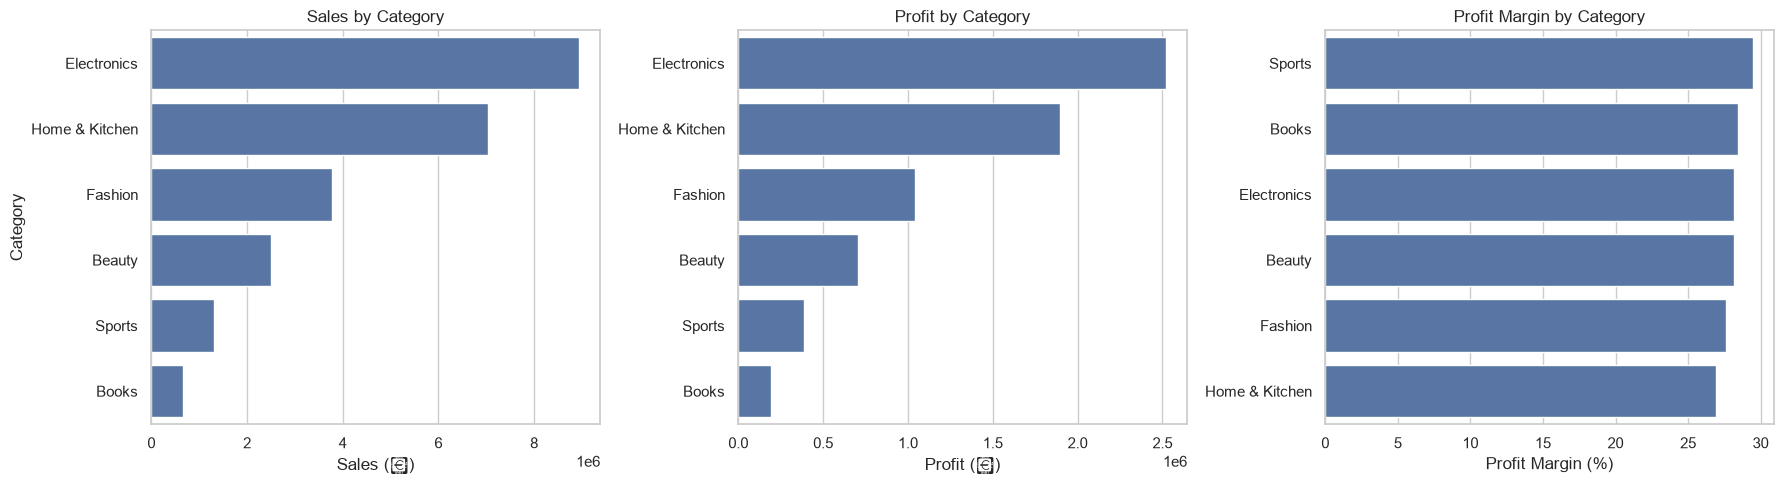

In [45]:
# Visualize category-wise sales, profit, and profit margin.

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.barplot(
    data=category_analysis,
    x="total_sales",
    y="category",
    ax=axes[0]
)
axes[0].set_title("Sales by Category")
axes[0].set_xlabel("Sales (₹)")
axes[0].set_ylabel("Category")

sns.barplot(
    data=category_analysis,
    x="total_profit",
    y="category",
    ax=axes[1]
)
axes[1].set_title("Profit by Category")
axes[1].set_xlabel("Profit (₹)")
axes[1].set_ylabel("")

sns.barplot(
    data=category_analysis.sort_values(
        "profit_margin_pct", ascending=False
    ),
    x="profit_margin_pct",
    y="category",
    ax=axes[2]
)
axes[2].set_title("Profit Margin by Category")
axes[2].set_xlabel("Profit Margin (%)")
axes[2].set_ylabel("")

plt.tight_layout()
plt.savefig(
    os.path.join(chart_dir, "02_category_performance.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [9]:
# Analyze sales and profitability across individual product sub-categories.

subcategory_analysis = (
    df.groupby("sub_category")
    .agg(
        total_orders=("order_id", "nunique"),
        total_units=("quantity", "sum"),
        total_sales=("sales_amount", "sum"),
        total_profit=("profit", "sum")
    )
    .reset_index()
    .sort_values("total_sales", ascending=False)
)

subcategory_analysis["profit_margin_pct"] = (
    subcategory_analysis["total_profit"] /
    subcategory_analysis["total_sales"] * 100
)

display(subcategory_analysis.round(2))

,sub_category,total_orders,total_units,total_sales,total_profit,profit_margin_pct
7,Kitchen,406,957,5891348.34,1566228.55,26.59
10,Wearables,461,1105,4932338.04,1351013.74,27.39
5,Footwear,400,997,2903839.21,784471.92,27.01
2,Audio,412,997,2259784.11,661441.39,29.27
8,Personal Care,397,952,1868923.05,520506.73,27.85
0,Accessories,446,1067,1741367.96,506661.08,29.10
4,Fitness,775,1837,1313003.05,386654.10,29.45
6,Home Decor,409,983,1149327.94,331074.91,28.81
1,Apparel,455,1070,874688.65,258894.00,29.60
3,Education,419,927,668277.53,190208.26,28.46


In [10]:
# Identify the top five products based on total sales.

top_products = (
    df.groupby(["product_id", "product_name", "category"])
    .agg(
        total_orders=("order_id", "nunique"),
        total_units=("quantity", "sum"),
        total_sales=("sales_amount", "sum"),
        total_profit=("profit", "sum")
    )
    .reset_index()
    .sort_values("total_sales", ascending=False)
    .head(5)
)

top_products["profit_margin_pct"] = (
    top_products["total_profit"] /
    top_products["total_sales"] * 100
)

display(top_products.round(2))


,product_id,product_name,category,total_orders,total_units,total_sales,total_profit,profit_margin_pct
3,SKU-0104,Air Fryer,Home & Kitchen,406,957,5891348.34,1566228.55,26.59
1,SKU-0102,Smart Watch,Electronics,461,1105,4932338.04,1351013.74,27.39
5,SKU-0106,Running Shoes,Fashion,400,997,2903839.21,784471.92,27.01
0,SKU-0101,Wireless Earbuds,Electronics,412,997,2259784.11,661441.39,29.27
8,SKU-0109,Hair Dryer,Beauty,397,952,1868923.05,520506.73,27.85


/var/folders/01/sgd5rw450c32b5c1ts5pl0vm0000gn/T/ipykernel_62792/2785858798.py:25: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/01/sgd5rw450c32b5c1ts5pl0vm0000gn/T/ipykernel_62792/2785858798.py:26: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  plt.savefig(
/Users/sanjeevjha/Desktop/Retail-Sales-Analysis/venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


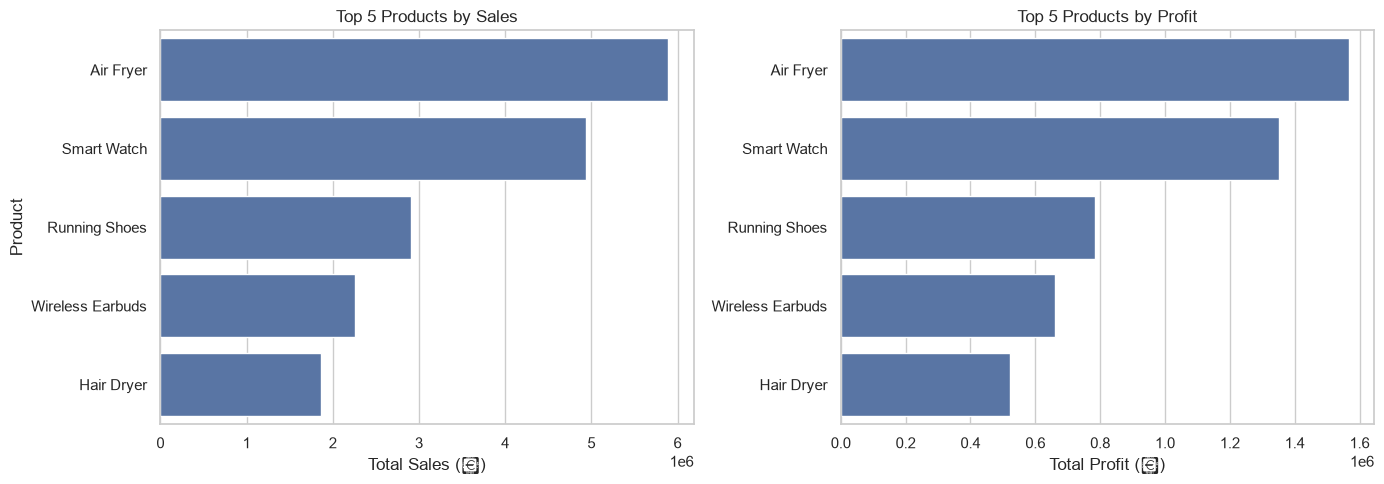

In [46]:
# Compare sales and profit generated by the top five products.

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(
    data=top_products,
    x="total_sales",
    y="product_name",
    ax=axes[0]
)
axes[0].set_title("Top 5 Products by Sales")
axes[0].set_xlabel("Total Sales (₹)")
axes[0].set_ylabel("Product")

sns.barplot(
    data=top_products,
    x="total_profit",
    y="product_name",
    ax=axes[1]
)
axes[1].set_title("Top 5 Products by Profit")
axes[1].set_xlabel("Total Profit (₹)")
axes[1].set_ylabel("")

plt.tight_layout()
plt.savefig(
    os.path.join(chart_dir, "03_top_5_products.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [12]:
# Identify new and repeat customers based on their order frequency.

customer_orders = (
    df.groupby("customer_id")
    .agg(
        total_orders=("order_id", "nunique"),
        total_sales=("sales_amount", "sum"),
        total_profit=("profit", "sum")
    )
    .reset_index()
)

customer_orders["customer_type"] = np.where(
    customer_orders["total_orders"] > 1,
    "Repeat Customer",
    "One-Time Customer"
)

customer_type_analysis = (
    customer_orders.groupby("customer_type")
    .agg(
        total_customers=("customer_id", "count"),
        total_orders=("total_orders", "sum"),
        total_sales=("total_sales", "sum"),
        total_profit=("total_profit", "sum")
    )
    .reset_index()
)

display(customer_type_analysis.round(2))

,customer_type,total_customers,total_orders,total_sales,total_profit
0,One-Time Customer,298,298,1455815.88,423122.45
1,Repeat Customer,1377,4702,22784731.82,6319025.58


In [13]:
# Identify the top ten customers based on their total purchase value.

top_customers = (
    customer_orders
    .sort_values("total_sales", ascending=False)
    .head(10)
    .reset_index(drop=True)
)

display(top_customers.round(2))

,customer_id,total_orders,total_sales,total_profit,customer_type
0,CUST-01731,6,80495.45,24821.78,Repeat Customer
1,CUST-01094,10,72084.25,16431.12,Repeat Customer
2,CUST-00498,5,68592.20,17798.22,Repeat Customer
3,CUST-01600,5,68586.55,20202.73,Repeat Customer
4,CUST-00294,7,66821.83,17617.08,Repeat Customer
5,CUST-01346,5,66587.90,21737.86,Repeat Customer
6,CUST-00287,6,66068.94,23580.79,Repeat Customer
7,CUST-01776,6,66051.50,22717.25,Repeat Customer
8,CUST-01118,6,62544.35,15944.00,Repeat Customer
9,CUST-00507,7,61848.79,20384.05,Repeat Customer


In [14]:
# Analyze sales and profitability across customer segments.

segment_analysis = (
    df.groupby("customer_segment")
    .agg(
        total_customers=("customer_id", "nunique"),
        total_orders=("order_id", "nunique"),
        total_sales=("sales_amount", "sum"),
        total_profit=("profit", "sum")
    )
    .reset_index()
    .sort_values("total_sales", ascending=False)
)

segment_analysis["profit_margin_pct"] = (
    segment_analysis["total_profit"] /
    segment_analysis["total_sales"] * 100
)

display(segment_analysis.round(2))


,customer_segment,total_customers,total_orders,total_sales,total_profit,profit_margin_pct
0,Loyalty,1086,1674,8220848.32,2248036.81,27.35
1,New,1080,1636,8029709.92,2246640.29,27.98
2,Returning,1059,1630,7708373.60,2158748.83,28.01


In [15]:
# Analyze customer distribution and business performance by gender.

gender_analysis = (
    df.groupby("gender")
    .agg(
        total_customers=("customer_id", "nunique"),
        total_orders=("order_id", "nunique"),
        total_sales=("sales_amount", "sum"),
        total_profit=("profit", "sum")
    )
    .reset_index()
    .sort_values("total_sales", ascending=False)
)

gender_analysis["profit_margin_pct"] = (
    gender_analysis["total_profit"] /
    gender_analysis["total_sales"] * 100
)

display(gender_analysis.round(2))

,gender,total_customers,total_orders,total_sales,total_profit,profit_margin_pct
0,Female,914,1275,6205697.54,1760185.67,28.36
3,Prefer not to say,888,1264,6157504.20,1673703.50,27.18
2,Non-binary,875,1226,5970593.06,1667626.68,27.93
1,Male,910,1235,5906752.90,1640632.18,27.78


/var/folders/01/sgd5rw450c32b5c1ts5pl0vm0000gn/T/ipykernel_62792/1457944697.py:27: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/01/sgd5rw450c32b5c1ts5pl0vm0000gn/T/ipykernel_62792/1457944697.py:28: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  plt.savefig(
/Users/sanjeevjha/Desktop/Retail-Sales-Analysis/venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


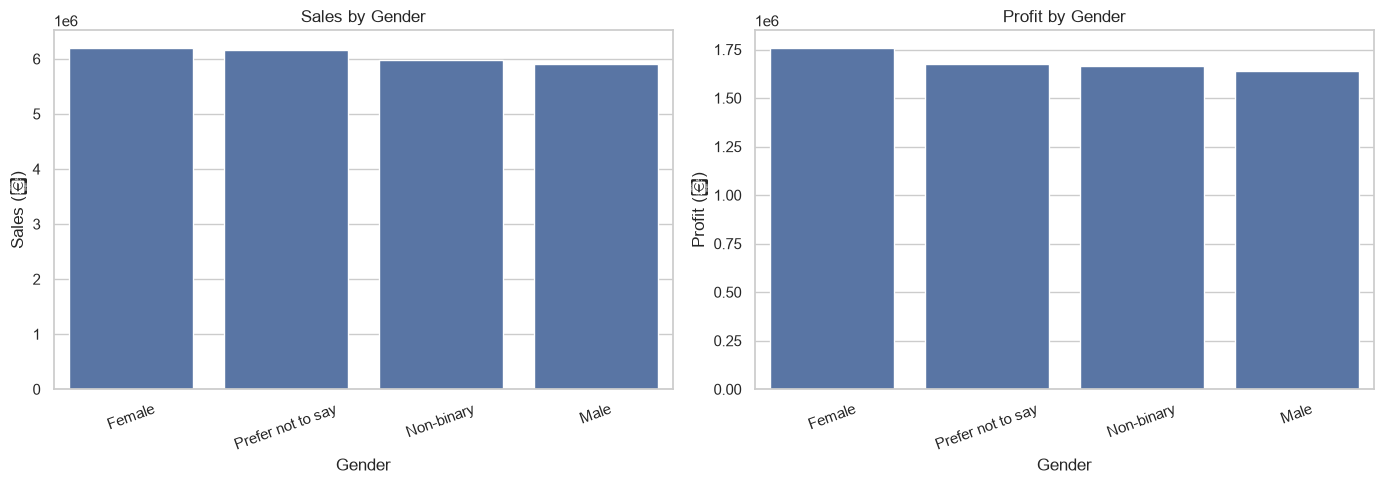

In [47]:
# Visualize gender-wise customer sales and profit performance.

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(
    data=gender_analysis,
    x="gender",
    y="total_sales",
    ax=axes[0]
)
axes[0].set_title("Sales by Gender")
axes[0].set_xlabel("Gender")
axes[0].set_ylabel("Sales (₹)")
axes[0].tick_params(axis="x", rotation=20)

sns.barplot(
    data=gender_analysis,
    x="gender",
    y="total_profit",
    ax=axes[1]
)
axes[1].set_title("Profit by Gender")
axes[1].set_xlabel("Gender")
axes[1].set_ylabel("Profit (₹)")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.savefig(
    os.path.join(chart_dir, "04_gender_analysis.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [17]:
# Analyze customer purchasing patterns across different age groups.

df["age_group"] = pd.cut(
    df["age"],
    bins=[17, 25, 35, 45, 55, 65],
    labels=[
        "18-25",
        "26-35",
        "36-45",
        "46-55",
        "56-65"
    ]
)

age_analysis = (
    df.dropna(subset=["age_group"])
    .groupby("age_group", observed=True)
    .agg(
        total_customers=("customer_id", "nunique"),
        total_orders=("order_id", "nunique"),
        total_sales=("sales_amount", "sum"),
        total_profit=("profit", "sum")
    )
    .reset_index()
)

age_analysis["profit_margin_pct"] = (
    age_analysis["total_profit"] /
    age_analysis["total_sales"] * 100
)

display(age_analysis.round(2))

,age_group,total_customers,total_orders,total_sales,total_profit,profit_margin_pct
0,18-25,670,852,4158932.12,1178365.80,28.33
1,26-35,777,1055,5291472.10,1450730.44,27.42
2,36-45,741,992,5005737.30,1353471.61,27.04
3,46-55,801,1040,4969742.54,1400911.95,28.19
4,56-65,758,989,4532465.03,1273821.40,28.10


/var/folders/01/sgd5rw450c32b5c1ts5pl0vm0000gn/T/ipykernel_62792/1515115445.py:25: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/01/sgd5rw450c32b5c1ts5pl0vm0000gn/T/ipykernel_62792/1515115445.py:26: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  plt.savefig(
/Users/sanjeevjha/Desktop/Retail-Sales-Analysis/venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


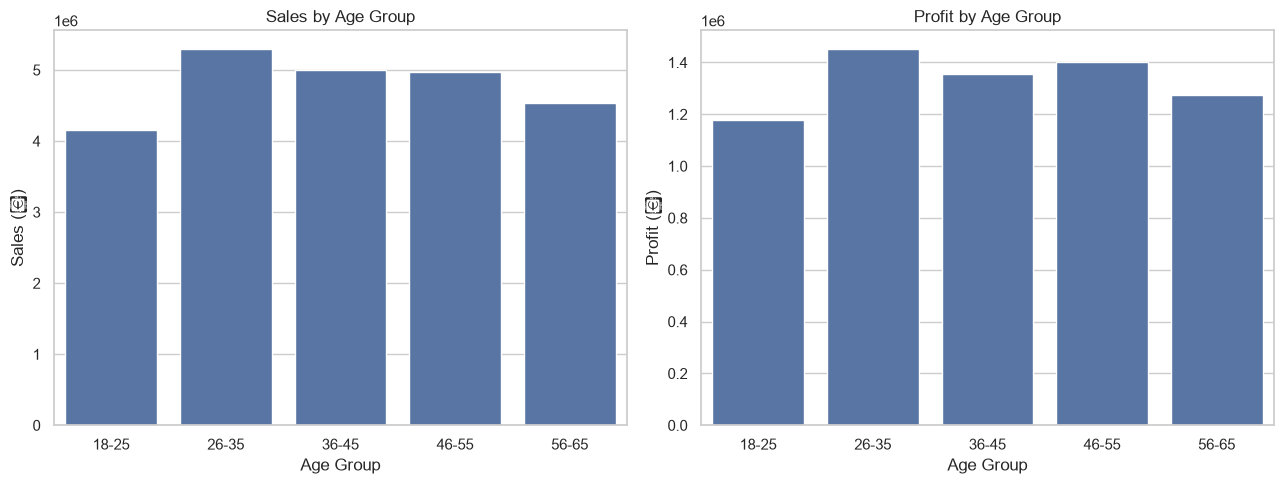

In [48]:
# Visualize sales and profit contribution across customer age groups.

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.barplot(
    data=age_analysis,
    x="age_group",
    y="total_sales",
    ax=axes[0]
)
axes[0].set_title("Sales by Age Group")
axes[0].set_xlabel("Age Group")
axes[0].set_ylabel("Sales (₹)")

sns.barplot(
    data=age_analysis,
    x="age_group",
    y="total_profit",
    ax=axes[1]
)
axes[1].set_title("Profit by Age Group")
axes[1].set_xlabel("Age Group")
axes[1].set_ylabel("Profit (₹)")

plt.tight_layout()
plt.savefig(
    os.path.join(chart_dir, "05_age_group_analysis.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [19]:
# Analyze sales, profit, and order distribution across states.

state_analysis = (
    df.groupby("state")
    .agg(
        total_customers=("customer_id", "nunique"),
        total_orders=("order_id", "nunique"),
        total_sales=("sales_amount", "sum"),
        total_profit=("profit", "sum")
    )
    .reset_index()
    .sort_values("total_sales", ascending=False)
)

state_analysis["profit_margin_pct"] = (
    state_analysis["total_profit"] /
    state_analysis["total_sales"] * 100
)

display(state_analysis.round(2))

,state,total_customers,total_orders,total_sales,total_profit,profit_margin_pct
5,Madhya Pradesh,609,757,3675558.54,1067828.80,29.05
6,Maharashtra,611,738,3477358.04,1005436.18,28.91
11,West Bengal,345,378,1925994.13,519765.30,26.99
1,Delhi,322,359,1871450.57,507114.88,27.10
3,Karnataka,319,352,1853117.61,496151.15,26.77
10,Uttar Pradesh,307,334,1698477.13,432652.55,25.47
8,Tamil Nadu,314,339,1692756.60,465511.93,27.50
9,Telangana,326,357,1691093.14,464047.74,27.44
7,Rajasthan,314,348,1684181.69,484257.80,28.75
0,Chandigarh,332,354,1681958.21,488527.94,29.05


/var/folders/01/sgd5rw450c32b5c1ts5pl0vm0000gn/T/ipykernel_62792/693825857.py:25: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/01/sgd5rw450c32b5c1ts5pl0vm0000gn/T/ipykernel_62792/693825857.py:26: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  plt.savefig(
/Users/sanjeevjha/Desktop/Retail-Sales-Analysis/venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


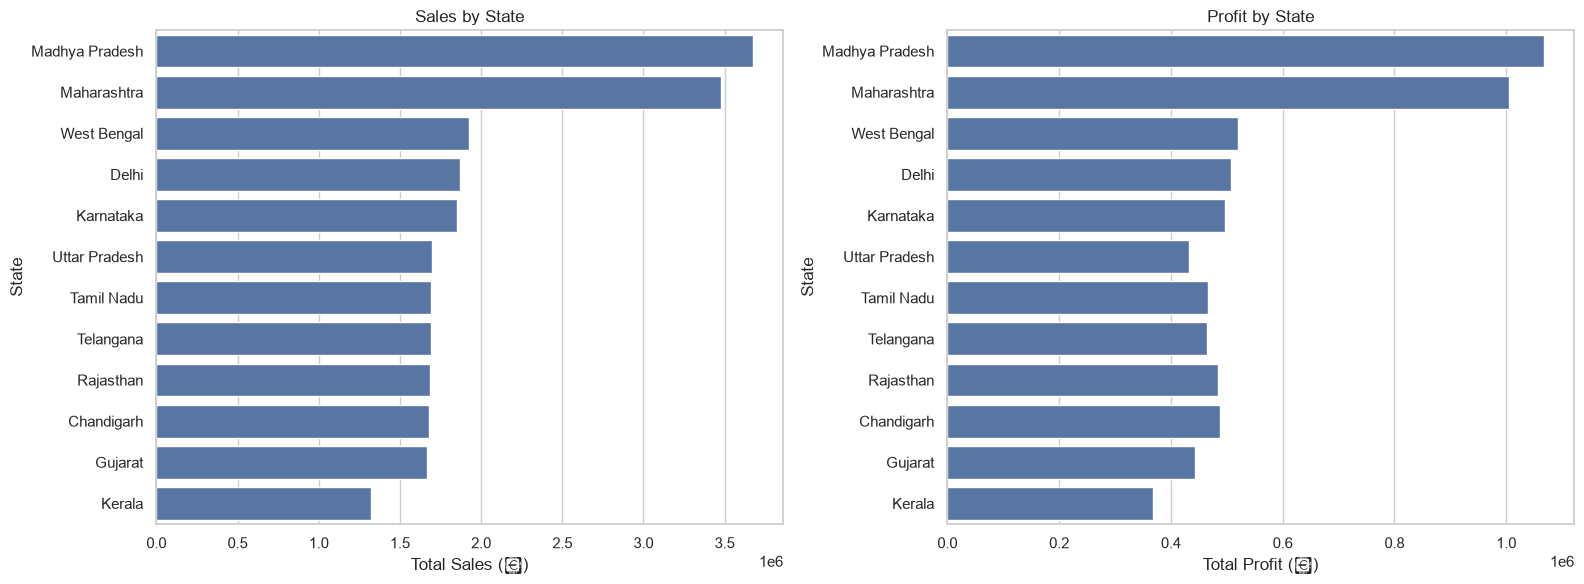

In [49]:
# Visualize state-wise sales and profit performance.

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(
    data=state_analysis,
    x="total_sales",
    y="state",
    ax=axes[0]
)
axes[0].set_title("Sales by State")
axes[0].set_xlabel("Total Sales (₹)")
axes[0].set_ylabel("State")

sns.barplot(
    data=state_analysis,
    x="total_profit",
    y="state",
    ax=axes[1]
)
axes[1].set_title("Profit by State")
axes[1].set_xlabel("Total Profit (₹)")
axes[1].set_ylabel("State")

plt.tight_layout()
plt.savefig(
    os.path.join(chart_dir, "06_state_wise_analysis.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [21]:
# Analyze sales, profit, and customer distribution across cities.

city_analysis = (
    df.groupby("city")
    .agg(
        total_customers=("customer_id", "nunique"),
        total_orders=("order_id", "nunique"),
        total_sales=("sales_amount", "sum"),
        total_profit=("profit", "sum")
    )
    .reset_index()
    .sort_values("total_sales", ascending=False)
)

city_analysis["profit_margin_pct"] = (
    city_analysis["total_profit"] /
    city_analysis["total_sales"] * 100
)

display(city_analysis.round(2))

,city,total_customers,total_orders,total_sales,total_profit,profit_margin_pct
2,Bhopal,352,392,1967383.49,574676.82,29.21
10,Kolkata,339,370,1872530.87,504237.21,26.93
5,Delhi,314,351,1827880.77,499118.05,27.31
1,Bengaluru,313,345,1809883.49,484965.22,26.80
12,Mumbai,340,367,1793403.94,507973.42,28.32
11,Lucknow,302,328,1683497.11,430784.04,25.59
6,Hyderabad,322,353,1681655.16,461843.66,27.46
3,Chandigarh,330,352,1664017.66,482856.31,29.02
8,Jaipur,307,341,1658877.89,475902.87,28.69
0,Ahmedabad,328,364,1658565.05,439741.99,26.51


/var/folders/01/sgd5rw450c32b5c1ts5pl0vm0000gn/T/ipykernel_62792/2175563218.py:25: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/01/sgd5rw450c32b5c1ts5pl0vm0000gn/T/ipykernel_62792/2175563218.py:26: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  plt.savefig(
/Users/sanjeevjha/Desktop/Retail-Sales-Analysis/venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


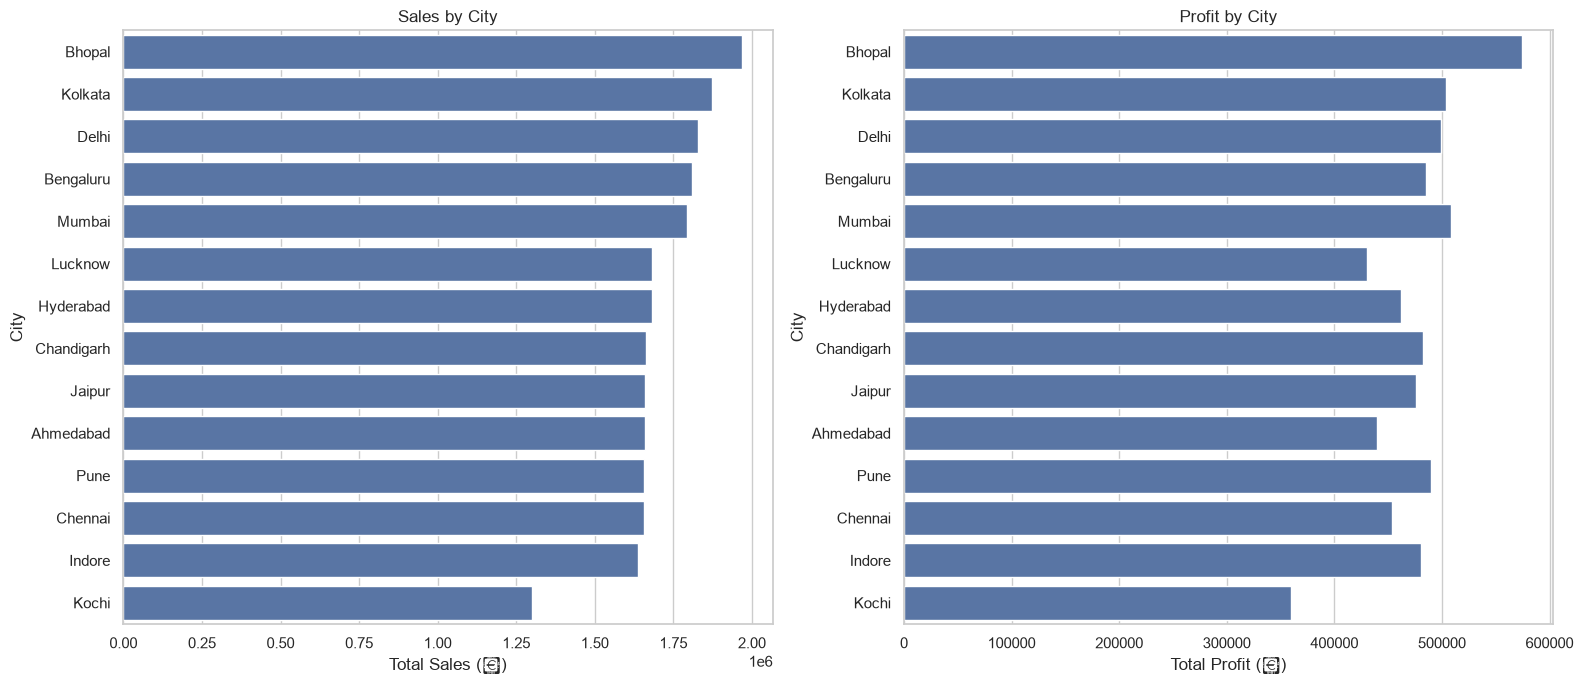

In [50]:
# Visualize city-wise sales and profit performance.

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

sns.barplot(
    data=city_analysis,
    x="total_sales",
    y="city",
    ax=axes[0]
)
axes[0].set_title("Sales by City")
axes[0].set_xlabel("Total Sales (₹)")
axes[0].set_ylabel("City")

sns.barplot(
    data=city_analysis,
    x="total_profit",
    y="city",
    ax=axes[1]
)
axes[1].set_title("Profit by City")
axes[1].set_xlabel("Total Profit (₹)")
axes[1].set_ylabel("City")

plt.tight_layout()
plt.savefig(
    os.path.join(chart_dir, "07_city_wise_analysis.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [23]:
# Analyze sales, orders, and profitability across payment methods.

payment_analysis = (
    df.groupby("payment_method")
    .agg(
        total_orders=("order_id", "nunique"),
        total_customers=("customer_id", "nunique"),
        total_sales=("sales_amount", "sum"),
        total_profit=("profit", "sum")
    )
    .reset_index()
    .sort_values("total_sales", ascending=False)
)

payment_analysis["profit_margin_pct"] = (
    payment_analysis["total_profit"] /
    payment_analysis["total_sales"] * 100
)

display(payment_analysis.round(2))


,payment_method,total_orders,total_customers,total_sales,total_profit,profit_margin_pct
0,Cash on Delivery,811,663,4120826.49,1162481.56,28.21
3,Net Banking,810,645,4029533.34,1109932.77,27.54
1,Credit Card,828,640,3998477.86,1118779.19,27.98
4,UPI,839,683,3996687.87,1093320.66,27.36
2,Debit Card,819,650,3858943.54,1058193.33,27.42
5,Wallet,768,616,3698388.64,1058107.48,28.61


In [24]:
# Analyze sales and profitability across different sales channels.

channel_analysis = (
    df.groupby("sales_channel")
    .agg(
        total_orders=("order_id", "nunique"),
        total_customers=("customer_id", "nunique"),
        total_sales=("sales_amount", "sum"),
        total_profit=("profit", "sum")
    )
    .reset_index()
    .sort_values("total_sales", ascending=False)
)

channel_analysis["profit_margin_pct"] = (
    channel_analysis["total_profit"] /
    channel_analysis["total_sales"] * 100
)

display(channel_analysis.round(2))

,sales_channel,total_orders,total_customers,total_sales,total_profit,profit_margin_pct
1,Mobile App,1291,924,6374136.12,1766626.68,27.72
2,Store,1261,912,6175006.61,1741793.79,28.21
0,Marketplace,1245,868,5927489.08,1673431.81,28.23
3,Website,1203,859,5763915.89,1560295.75,27.07


/var/folders/01/sgd5rw450c32b5c1ts5pl0vm0000gn/T/ipykernel_62792/609659721.py:27: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/01/sgd5rw450c32b5c1ts5pl0vm0000gn/T/ipykernel_62792/609659721.py:28: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  plt.savefig(
/Users/sanjeevjha/Desktop/Retail-Sales-Analysis/venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


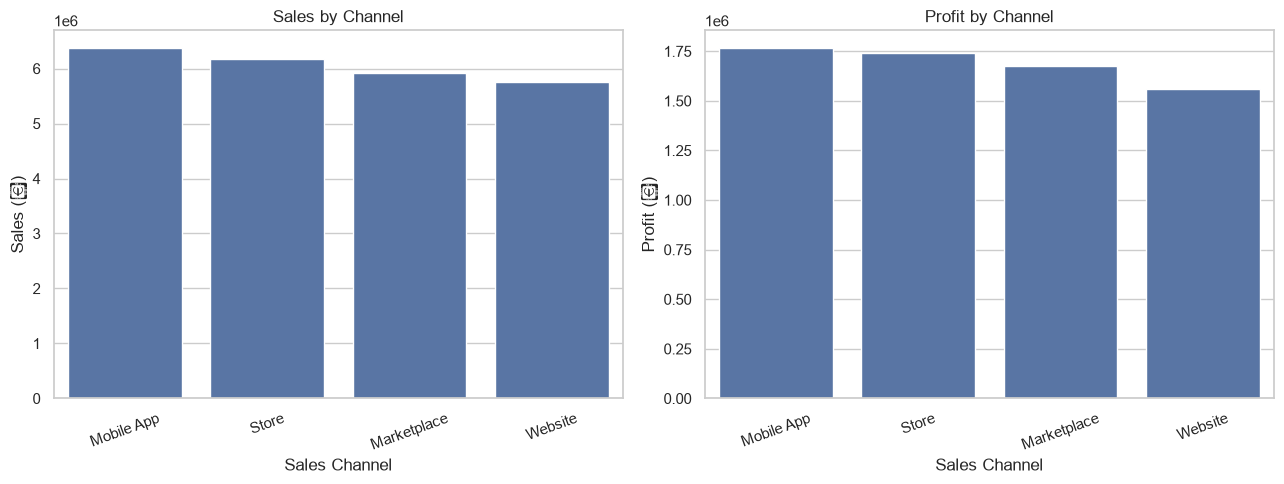

In [60]:
# Visualize sales and profit performance across sales channels.

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.barplot(
    data=channel_analysis,
    x="sales_channel",
    y="total_sales",
    ax=axes[0]
)
axes[0].set_title("Sales by Channel")
axes[0].set_xlabel("Sales Channel")
axes[0].set_ylabel("Sales (₹)")
axes[0].tick_params(axis="x", rotation=20)

sns.barplot(
    data=channel_analysis,
    x="sales_channel",
    y="total_profit",
    ax=axes[1]
)
axes[1].set_title("Profit by Channel")
axes[1].set_xlabel("Sales Channel")
axes[1].set_ylabel("Profit (₹)")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.savefig(
    os.path.join(chart_dir, "08_sales_channel_analysis.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [26]:
# Analyze order distribution, sales, and profit across order statuses.

status_analysis = (
    df.groupby("order_status")
    .agg(
        total_orders=("order_id", "nunique"),
        total_sales=("sales_amount", "sum"),
        total_profit=("profit", "sum")
    )
    .reset_index()
    .sort_values("total_orders", ascending=False)
)

status_analysis["order_percentage"] = (
    status_analysis["total_orders"] /
    status_analysis["total_orders"].sum() * 100
)

status_analysis["profit_margin_pct"] = (
    status_analysis["total_profit"] /
    status_analysis["total_sales"] * 100
)

display(status_analysis.round(2))

,order_status,total_orders,total_sales,total_profit,order_percentage,profit_margin_pct
1,Delivered,3444,16346271.60,4568671.14,68.88,27.95
4,Shipped,532,2847205.45,778162.32,10.64,27.33
2,Processing,380,1940163.23,529708.12,7.60,27.30
0,Cancelled,350,1737299.06,480072.47,7.00,27.63
3,Returned,294,1369608.36,385533.98,5.88,28.15


/var/folders/01/sgd5rw450c32b5c1ts5pl0vm0000gn/T/ipykernel_62792/2255020474.py:27: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/01/sgd5rw450c32b5c1ts5pl0vm0000gn/T/ipykernel_62792/2255020474.py:28: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  plt.savefig(
/Users/sanjeevjha/Desktop/Retail-Sales-Analysis/venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


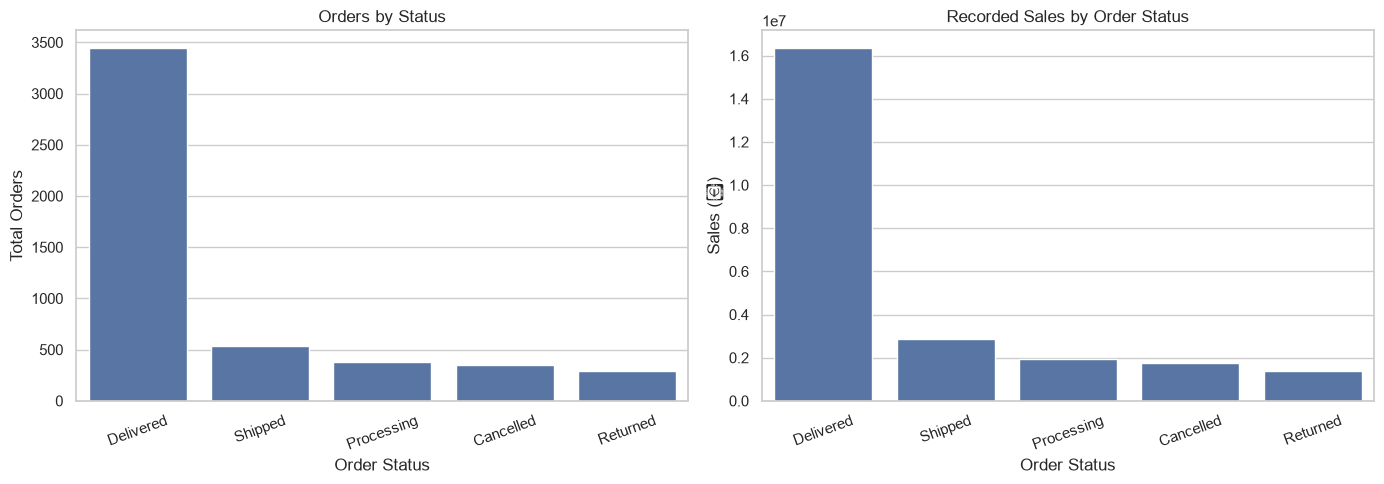

In [52]:
# Visualize order distribution and status-wise sales.

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(
    data=status_analysis,
    x="order_status",
    y="total_orders",
    ax=axes[0]
)
axes[0].set_title("Orders by Status")
axes[0].set_xlabel("Order Status")
axes[0].set_ylabel("Total Orders")
axes[0].tick_params(axis="x", rotation=20)

sns.barplot(
    data=status_analysis,
    x="order_status",
    y="total_sales",
    ax=axes[1]
)
axes[1].set_title("Recorded Sales by Order Status")
axes[1].set_xlabel("Order Status")
axes[1].set_ylabel("Sales (₹)")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.savefig(
    os.path.join(chart_dir, "09_order_status_analysis.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [28]:
# Analyze the relationship between discount levels and profitability.

df["discount_group"] = pd.cut(
    df["discount_pct"],
    bins=[-0.01, 5, 10, 15, 20, 25],
    labels=[
        "0-5%",
        "5-10%",
        "10-15%",
        "15-20%",
        "20-25%"
    ],
    include_lowest=True
)

discount_analysis = (
    df.dropna(subset=["discount_group"])
    .groupby("discount_group", observed=True)
    .agg(
        total_orders=("order_id", "nunique"),
        total_sales=("sales_amount", "sum"),
        total_profit=("profit", "sum"),
        average_discount=("discount_pct", "mean")
    )
    .reset_index()
)

discount_analysis["profit_margin_pct"] = (
    discount_analysis["total_profit"] /
    discount_analysis["total_sales"] * 100
)

display(discount_analysis.round(2))

,discount_group,total_orders,total_sales,total_profit,average_discount,profit_margin_pct
0,0-5%,1881,9882399.61,3402285.84,1.75,34.43
1,5-10%,1199,5840856.71,1653985.60,10.00,28.32
2,10-15%,607,2726781.80,667543.21,15.00,24.48
3,15-20%,613,2626252.28,501593.19,20.00,19.10
4,20-25%,594,2658129.54,380962.43,25.00,14.33


In [29]:
# Analyze delivery performance and customer ratings.

delivery_analysis = (
    df[df["order_status"] == "Delivered"]
    .dropna(subset=["delivery_days"])
    .groupby("delivery_days")
    .agg(
        total_orders=("order_id", "nunique"),
        average_rating=("product_rating", "mean"),
        total_sales=("sales_amount", "sum")
    )
    .reset_index()
    .sort_values("delivery_days")
)

display(delivery_analysis.round(2))

,delivery_days,total_orders,average_rating,total_sales
0,1.0,379,3.07,1643074.13
1,2.0,328,2.98,1564753.08
2,3.0,415,2.98,1843054.50
3,4.0,356,3.11,1635487.92
4,5.0,376,2.96,1867593.19
5,6.0,382,3.06,1890651.02
6,7.0,381,2.91,1876693.78
7,8.0,364,2.96,1750381.42
8,9.0,346,3.04,1787456.00


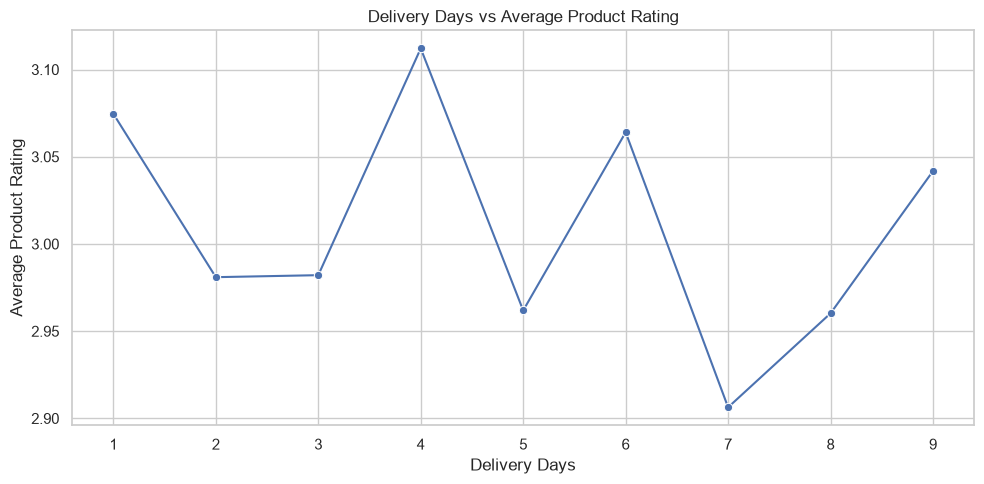

In [53]:
# Visualize delivery time against average product ratings.

plt.figure(figsize=(10, 5))

sns.lineplot(
    data=delivery_analysis,
    x="delivery_days",
    y="average_rating",
    marker="o"
)

plt.title("Delivery Days vs Average Product Rating")
plt.xlabel("Delivery Days")
plt.ylabel("Average Product Rating")
plt.xticks(range(1, 10))
plt.tight_layout()
plt.savefig(
    os.path.join(chart_dir, "10_delivery_day_vs_rating_analysis.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [32]:
# Calculate correlations between numerical business variables.

numeric_columns = [
    "age",
    "quantity",
    "unit_price",
    "discount_pct",
    "shipping_fee",
    "sales_amount",
    "cost_amount",
    "profit",
    "delivery_days",
    "product_rating"
]

correlation_matrix = df[numeric_columns].corr()

display(correlation_matrix.round(2))

,age,quantity,unit_price,discount_pct,shipping_fee,sales_amount,cost_amount,profit,delivery_days,product_rating
age,1.00,-0.01,-0.03,0.01,-0.00,-0.02,-0.02,-0.02,-0.04,0.01
quantity,-0.01,1.00,0.01,-0.01,-0.00,0.53,0.52,0.45,0.00,-0.00
unit_price,-0.03,0.01,1.00,0.02,0.00,0.73,0.72,0.58,0.04,0.01
discount_pct,0.01,-0.01,0.02,1.00,0.01,-0.07,0.02,-0.24,-0.02,-0.04
shipping_fee,-0.00,-0.00,0.00,0.01,1.00,-0.00,-0.01,0.03,-0.03,0.02
sales_amount,-0.02,0.53,0.73,-0.07,-0.00,1.00,0.97,0.85,0.04,0.01
cost_amount,-0.02,0.52,0.72,0.02,-0.01,0.97,1.00,0.71,0.03,0.01
profit,-0.02,0.45,0.58,-0.24,0.03,0.85,0.71,1.00,0.04,0.01
delivery_days,-0.04,0.00,0.04,-0.02,-0.03,0.04,0.03,0.04,1.00,-0.01
product_rating,0.01,-0.00,0.01,-0.04,0.02,0.01,0.01,0.01,-0.01,1.00


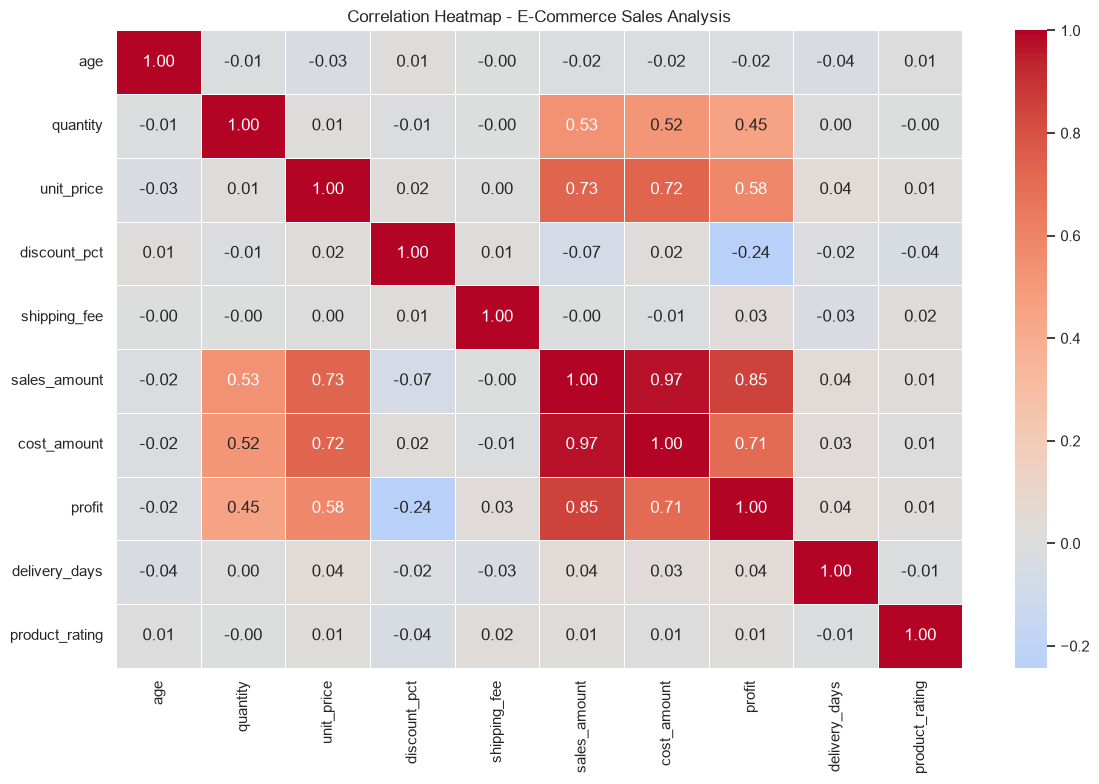

In [61]:
# Visualize correlations between numerical business variables.

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    center=0
)

plt.title("Correlation Heatmap - E-Commerce Sales Analysis")
plt.tight_layout()
plt.savefig(
    os.path.join(chart_dir, "11_sales_correlation_heatmap.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [34]:
# Identify orders that generated negative profit.

loss_orders = df[df["profit"] < 0].copy()

total_loss_orders = loss_orders["order_id"].nunique()
total_loss_amount = abs(loss_orders["profit"].sum())

print("Total Loss-Making Orders:", total_loss_orders)
print("Total Loss Amount: ₹", round(total_loss_amount, 2))

Total Loss-Making Orders: 116
Total Loss Amount: ₹ 26364.0


In [35]:
# Analyze loss-making orders across product categories.

category_loss = (
    loss_orders.groupby("category")
    .agg(
        loss_orders=("order_id", "nunique"),
        total_loss=("profit", "sum")
    )
    .reset_index()
    .sort_values("total_loss")
)

category_loss["total_loss"] = category_loss["total_loss"].abs()

display(category_loss.round(2))

,category,loss_orders,total_loss
4,Home & Kitchen,26,10888.44
2,Electronics,28,9224.58
3,Fashion,22,3479.11
0,Beauty,16,1669.47
5,Sports,9,578.26
1,Books,15,524.14


/var/folders/01/sgd5rw450c32b5c1ts5pl0vm0000gn/T/ipykernel_62792/1182336491.py:15: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/01/sgd5rw450c32b5c1ts5pl0vm0000gn/T/ipykernel_62792/1182336491.py:16: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  plt.savefig(
/Users/sanjeevjha/Desktop/Retail-Sales-Analysis/venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


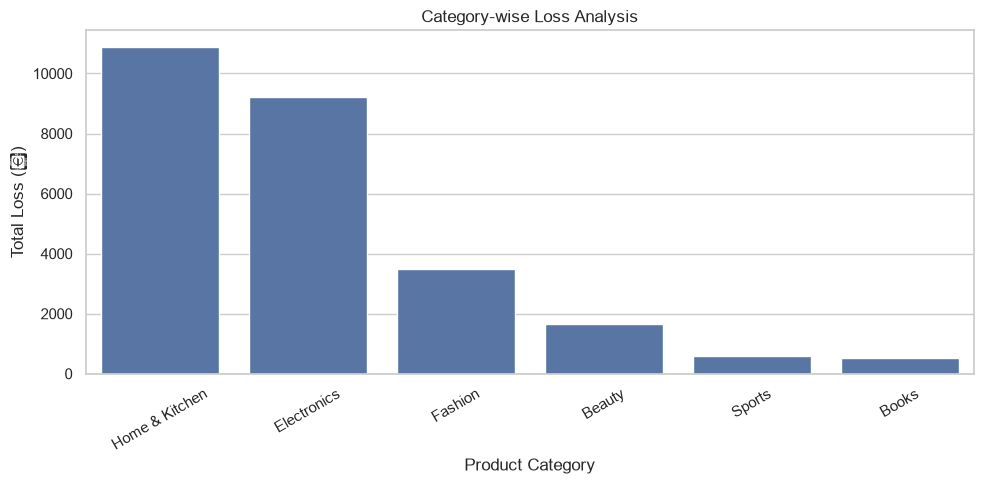

In [62]:
# Visualize total loss across product categories.

plt.figure(figsize=(10, 5))

sns.barplot(
    data=category_loss,
    x="category",
    y="total_loss"
)

plt.title("Category-wise Loss Analysis")
plt.xlabel("Product Category")
plt.ylabel("Total Loss (₹)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig(
    os.path.join(chart_dir, "12_category_wise_loss.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [37]:
# Identify products generating negative profit.

product_loss = (
    loss_orders.groupby(["product_id", "product_name", "category"])
    .agg(
        loss_orders=("order_id", "nunique"),
        total_loss=("profit", "sum")
    )
    .reset_index()
    .sort_values("total_loss")
)

product_loss["total_loss"] = product_loss["total_loss"].abs()

display(product_loss.head(10).round(2))

,product_id,product_name,category,loss_orders,total_loss
3,SKU-0104,Air Fryer,Home & Kitchen,16,10064.18
1,SKU-0102,Smart Watch,Electronics,14,7543.69
5,SKU-0106,Running Shoes,Fashion,11,2811.71
2,SKU-0103,USB-C Hub,Electronics,10,1577.73
8,SKU-0109,Hair Dryer,Beauty,9,1176.87
4,SKU-0105,LED Desk Lamp,Home & Kitchen,10,824.26
6,SKU-0107,Cotton T-Shirt,Fashion,11,667.40
11,SKU-0112,Data Analytics Handbook,Books,15,524.14
7,SKU-0108,Vitamin C Serum,Beauty,7,492.60
10,SKU-0111,Resistance Bands,Sports,6,352.79


/var/folders/01/sgd5rw450c32b5c1ts5pl0vm0000gn/T/ipykernel_62792/3834620500.py:14: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/01/sgd5rw450c32b5c1ts5pl0vm0000gn/T/ipykernel_62792/3834620500.py:15: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  plt.savefig(
/Users/sanjeevjha/Desktop/Retail-Sales-Analysis/venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


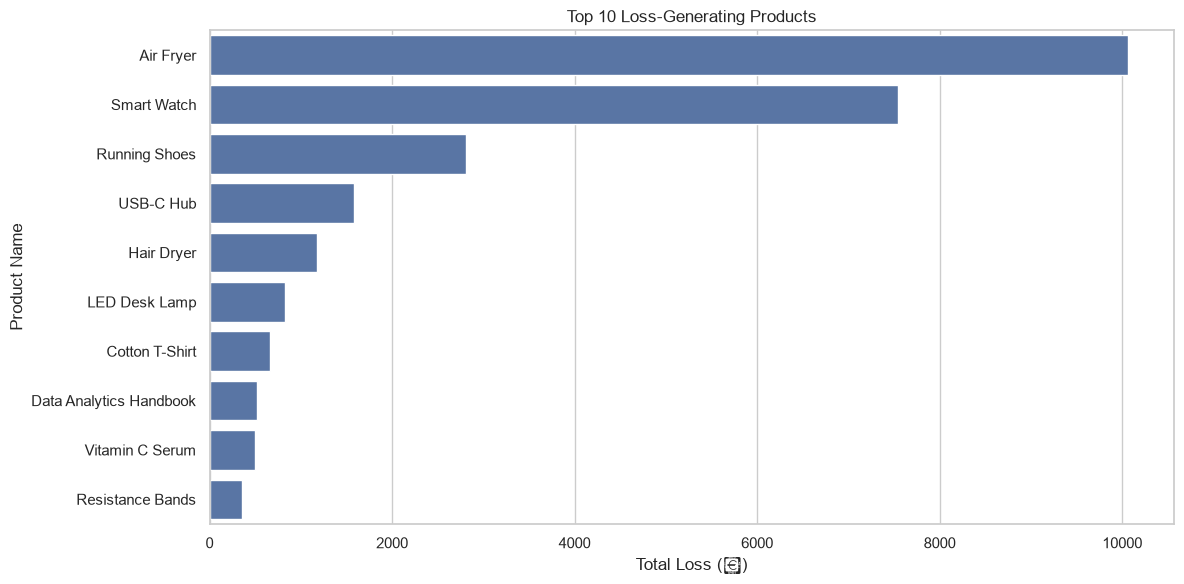

In [56]:
# Visualize the top 10 products generating losses.

plt.figure(figsize=(12, 6))

sns.barplot(
    data=product_loss.head(10),
    x="total_loss",
    y="product_name"
)

plt.title("Top 10 Loss-Generating Products")
plt.xlabel("Total Loss (₹)")
plt.ylabel("Product Name")
plt.tight_layout()
plt.savefig(
    os.path.join(chart_dir, "13_product-wise_Loss_Analysis.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [64]:
# Verify all exported chart files.

import os

chart_files = sorted(os.listdir(chart_dir))

print("Total exported charts:", len(chart_files))
print("\nChart filenames:")

for file in chart_files:
    print(file)

Total exported charts: 14

Chart filenames:
01_monthly_sales_profit.png
02_category_performance.png
03_top_5_products.png
04_gender_analysis.png
05_age_group_analysis.png
06_state_wise_analysis.png
07_city_wise_analysis.png
08_sales_channel_analysis.png
09_order_status_analysis.png
10_delivery_day_vs_rating_analysis.png
11_sales_correlation_heatmap.png
12_category-wise_Loss_Analysis.png
12_category_wise_loss.png
13_product-wise_Loss_Analysis.png


# Business Insights & Recommendations

## 1. Sales Performance
- Total recorded sales were ₹2.42 crore.
- Total recorded profit was ₹67.42 lakh.
- Overall profit margin was 27.81%.
- January recorded the highest monthly sales, while September recorded the lowest.

## 2. Product Performance
- Electronics generated the highest category sales and profit.
- Home & Kitchen recorded the highest subcategory sales.
- Air Fryer was the highest-selling product by sales value.
- Sports category achieved the highest profit margin at 29.45%.

## 3. Customer Behaviour
- Repeat customers contributed approximately 93.99% of recorded sales.
- The 26–35 age group generated the highest sales.
- Female customers recorded the highest sales among gender groups.
- Loyalty customers represented the largest customer segment by sales.

## 4. Geographic Performance
- Madhya Pradesh recorded the highest state-level sales and profit.
- Bhopal recorded the highest city-level sales and profit.
- Pune achieved the highest city-level profit margin at 29.53%.

## 5. Payment & Sales Channel
- Cash on Delivery generated the highest sales among payment methods.
- Mobile App recorded the highest sales among sales channels.
- Marketplace achieved the highest channel-level profit margin at 28.23%.

## 6. Discount & Profitability
- The 0–5% discount group achieved the highest profit margin of 34.43%.
- The 20–25% discount group had the lowest profit margin of 14.33%.
- Higher discount bands were associated with lower profit margins.

## 7. Delivery Performance
- Average product ratings varied between 2.91 and 3.11 across delivery-day groups.
- No strong linear relationship was observed between delivery days and product ratings.

## 8. Loss Analysis
- 116 orders generated negative profit.
- Total loss amounted to ₹26,364.
- Home & Kitchen recorded the highest category-level loss.
- Air Fryer was the highest loss-generating product.

## Business Recommendations
1. Focus on high-performing products and categories while monitoring their profit margins.
2. Develop loyalty and retention strategies to maintain repeat customer contribution.
3. Review discount policies, especially high-discount campaigns.
4. Investigate the cost and pricing structure of Air Fryer and Smart Watch products.
5. Monitor loss-making orders to identify potential pricing or cost-related issues.
6. Continue monitoring sales performance across states, cities and channels.
7. Improve customer experience by tracking delivery performance and product ratings.